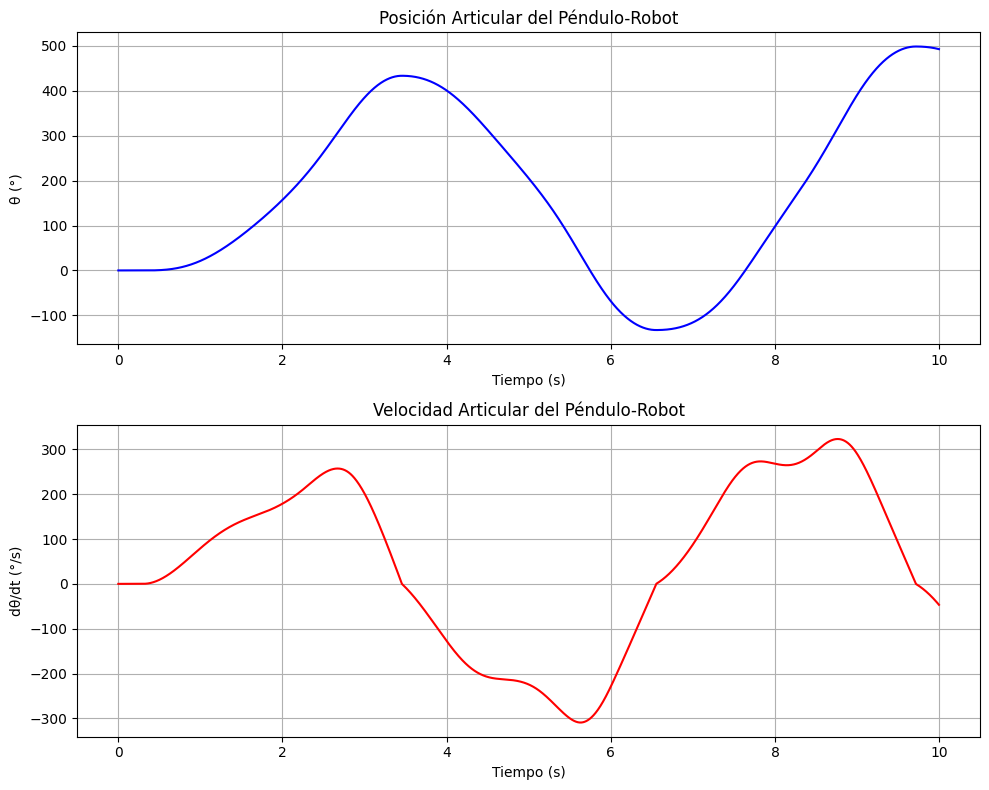

Posición máxima:  8.70 rad (498.4°)
Posición mínima:  -2.32 rad (-132.7°)
Posición final:   8.60 rad (492.5°)
Velocidad máxima: 5.64 rad/s
Velocidad mínima: -5.40 rad/s


In [6]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# -----------------------------------------------------------------
# SIMULACIÓN DE UN PÉNDULO ROBOT (Python)
# Modelo de Euler-Lagrange:
#   Ir*qpp + m*g*lc*sin(q) + b*qp + fc*sign(qp) = tau
# Estados: X1 = q (posición), X2 = qp (velocidad)
# -----------------------------------------------------------------

def f(t, x):
    # Parámetros del modelo (valores dados en la actividad)
    m = 5.0      # Masa de todo el mecanismo (kg)
    lc = 0.01    # Distancia al centro de masa (m)
    g = 9.81     # Gravedad (m/s^2)
    b = 0.14     # Fricción viscosa (N·m·s/rad)
    fc = 0.45    # Fricción de Coulomb (N·m)
    Ir = 0.16    # Inercia rotacional (kg·m^2)

    X1 = x[0]    # Posición q (rad)
    X2 = x[1]    # Velocidad qp (rad/s)

    tau_motor = tau(t)

    # tanh() aproxima sign() de forma suave
    friccion_coulomb = fc * np.tanh(1000 * X2)

    dX1 = X2
    dX2 = (1/Ir) * (tau_motor - m*g*lc*np.sin(X1) - b*X2 - friccion_coulomb)

    return [dX1, dX2]

def tau(t):
    # Par senoidal con amplitud de 1.5 N·m
    return 1.5 * np.sin(t)

# --- Simulación ---
ti = 0.0
tf = 10.0
h = 0.0025
ts = np.arange(ti, tf, h)

# Condiciones iniciales: X1 = 0, X2 = 0
x0 = [0.0, 0.0]

sol = solve_ivp(f, [ti, tf], x0, t_eval=ts)

t = sol.t
posicion = sol.y[0]
velocidad = sol.y[1]

posicion_grados = np.rad2deg(posicion)
velocidad_grados = np.rad2deg(velocidad)

# --- Gráficas ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

ax1.plot(t, posicion_grados, 'b-')
ax1.set_xlabel('Tiempo (s)')
ax1.set_ylabel('θ (°)')
ax1.set_title('Posición Articular del Péndulo-Robot')
ax1.grid(True)

ax2.plot(t, velocidad_grados, 'r-')
ax2.set_xlabel('Tiempo (s)')
ax2.set_ylabel('dθ/dt (°/s)')
ax2.set_title('Velocidad Articular del Péndulo-Robot')
ax2.grid(True)

plt.tight_layout()
plt.show()

# Valores para la conclusión
print(f"Posición máxima:  {posicion.max():.2f} rad ({posicion_grados.max():.1f}°)")
print(f"Posición mínima:  {posicion.min():.2f} rad ({posicion_grados.min():.1f}°)")
print(f"Posición final:   {posicion[-1]:.2f} rad ({posicion_grados[-1]:.1f}°)")
print(f"Velocidad máxima: {velocidad.max():.2f} rad/s")
print(f"Velocidad mínima: {velocidad.min():.2f} rad/s")